In [1]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: c:\Users\Eduardo\Desktop\Dev\Proyectos\urbanos\ml\.venv\Scripts\python.exe
PyTorch: 2.11.0+cu128
CUDA disponible: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


# Comparativo de modelos preentrenados para detectar daño en calles
**Proyecto UrbanOS · Visión por computadora · Maestría en IA**

**Caso de uso.** UrbanOS es una plataforma municipal para revisar el estado de las calles. Antes de contar y ubicar cada bache, el sistema debe decidir si una foto muestra un bache o una calle sin daño. En este cuaderno comparo tres modelos preentrenados de Hugging Face en esa tarea.

**Tarea.** Clasificación binaria de imágenes: `bache` (clase positiva) y `sin_dano`.

**Ajuste mínimo.** Los modelos no se reentrenan. Los uso congelados como extractores de características y entreno encima una regresión logística.

**Entorno.** Google Colab con GPU T4 y un token de lectura de Hugging Face guardado en los Secretos de Colab (`HF_TOKEN`).

## 1. Configuración de GPU

In [2]:
import platform, sys, torch

print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__)

HAY_GPU = torch.cuda.is_available()
DISPOSITIVO = torch.device("cuda" if HAY_GPU else "cpu")

print("GPU:", torch.cuda.get_device_name(0) if HAY_GPU else "no disponible, se usa CPU")

Python: 3.11.9 | PyTorch: 2.11.0+cu128
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 2. Instalación de dependencias

In [ ]:
# Las dependencias se instalan siguiendo las instrucciones del README.md.
# No instalar paquetes automáticamente desde esta celda.
# PyTorch y Torchvision deben instalarse según la plataforma y la GPU.

## 3. Parámetros del experimento

In [4]:

import os
import json
import random
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEMILLA = 42
MAX_POR_CLASE = None
MEDIR_CPU = True
N_LATENCIA = 100
ANCHO_LOTE = 8 

MODELOS = {
    "MobileNetV2": "google/mobilenet_v2_1.0_224",
    "ResNet-50": "microsoft/resnet-50",
    "ViT-Base": "google/vit-base-patch16-224",
}

FUENTE_DATASET = {
    "nombre": "Pothole Detection Dataset",
    "autor": "Atulya Kumar",
    "url": "https://www.kaggle.com/datasets/atulyakumar98/pothole-detection-dataset",
    "licencia": "CC0: Public Domain",
    "fecha_descarga": "2026-10-10",
    "descripcion": (
        "681 imágenes originales: 352 en normal y 329 en potholes."
    ),
}


candidatas = [Path.cwd(), *Path.cwd().parents]
PROYECTO = next(
    (
        ruta for ruta in candidatas
        if (ruta / "src" / "datos.py").is_file()
        and (ruta / "data" / "raw").is_dir()
    ),
    None,
)

if PROYECTO is None:
    raise FileNotFoundError(
        "No encuentro la carpeta ml. Comprueba que abriste el proyecto correcto."
    )

RAW = PROYECTO / "data" / "raw"
RESULTADOS = PROYECTO / "results"
RUTA_ZIP = RAW / "dataset.zip"

RESULTADOS.mkdir(parents=True, exist_ok=True)
os.chdir(PROYECTO)

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print("Proyecto:", PROYECTO)
print("Datos:", RAW)
print("Resultados:", RESULTADOS)
print("Imágenes encontradas:", sum(1 for p in RAW.rglob("*") if p.is_file()))
print("Dispositivo:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Proyecto: c:\Users\Eduardo\Desktop\Dev\Proyectos\urbanos\ml
Datos: c:\Users\Eduardo\Desktop\Dev\Proyectos\urbanos\ml\data\raw
Resultados: c:\Users\Eduardo\Desktop\Dev\Proyectos\urbanos\ml\results
Imágenes encontradas: 682
Dispositivo: NVIDIA GeForce RTX 4050 Laptop GPU


## 4. Autenticación en Hugging Face Hub
Inicio sesión con un token de lectura guardado en los Secretos de Colab (`HF_TOKEN`).

In [5]:

from huggingface_hub import HfApi

api = HfApi()
print("Conexión con Hugging Face disponible.")

Conexión con Hugging Face disponible.


## 5. Dataset
Uso el *Pothole Detection Dataset* de Atulya Kumar, publicado en Kaggle con licencia CC0: 681 archivos en dos carpetas, `normal` y `potholes`. Descargué el ZIP y lo subí a Colab como `dataset.zip`.

La clase de cada imagen se deduce del nombre de su carpeta. Quito imágenes dañadas, duplicados exactos y duplicados con etiquetas contradictorias, y hago una división propia `train / val / test` de 70 / 15 / 15, con semilla fija y proporción de clases conservada. El código de preparación está en `src/datos.py` y `src/metricas.py`.

In [6]:
import subprocess
import sys
import zipfile

RUTA_MANIFIESTO = PROYECTO / "data" / "dataset.csv"
CARPETA_NORMAL = RAW / "normal"
CARPETA_BACHES = RAW / "potholes"


hay_imagenes = (
    CARPETA_NORMAL.is_dir()
    and CARPETA_BACHES.is_dir()
    and any(CARPETA_NORMAL.iterdir())
    and any(CARPETA_BACHES.iterdir())
)


if not hay_imagenes:
    if not RUTA_ZIP.is_file():
        raise FileNotFoundError(
            f"No se encontró el archivo ZIP: {RUTA_ZIP}"
        )

    print("Descomprimiendo el dataset...")

    with zipfile.ZipFile(RUTA_ZIP, "r") as archivo_zip:
        archivo_zip.extractall(RAW)

    print("Descompresión terminada.")


if not RUTA_MANIFIESTO.is_file():
    print("Generando el manifiesto del dataset...")

    subprocess.run(
        [
            sys.executable,
            "-m",
            "src.preparar_dataset",
            "--raiz",
            str(RAW),
            "--salida",
            str(PROYECTO / "data"),
            "--semilla",
            str(SEMILLA),
        ],
        cwd=str(PROYECTO),
        check=True,
    )


manifiesto = pd.read_csv(RUTA_MANIFIESTO)

print("Manifiesto:", RUTA_MANIFIESTO)
print("Total de imágenes:", len(manifiesto))

print("\nImágenes por partición y clase:")
display(
    pd.crosstab(
        manifiesto["particion"],
        manifiesto["clase"],
        margins=True,
    )
)

print("\nPrimeras filas:")
display(manifiesto.head())

Manifiesto: c:\Users\Eduardo\Desktop\Dev\Proyectos\urbanos\ml\data\dataset.csv
Total de imágenes: 676

Imágenes por partición y clase:


clase,bache,sin_dano,All
particion,,,
test,49,53,102
train,229,243,472
val,49,53,102
All,327,349,676



Primeras filas:


,id,ruta_relativa,clase,etiqueta,particion,ancho_px,alto_px,tamano_kb,md5
0,img_00001,normal/1.jpg,sin_dano,0,train,280,150,11.5,73837a1a75d0dc98326e8992d3cae729
1,img_00002,normal/10.jpg,sin_dano,0,train,870,290,136.9,b7415f1b2a2d77b350d753b75807f736
2,img_00003,normal/100.jpg,sin_dano,0,train,640,480,40.3,3b0a970fc4f1c4648a379628c745ec9a
3,img_00004,normal/101.jpg,sin_dano,0,train,1024,680,209.8,8e2b95bec3cd8a4996f7a11d53a034d6
4,img_00005,normal/102.jpg,sin_dano,0,test,768,512,88.3,3457f06ec5f72ebd9fcb1dab379caf1b


In [7]:

%%writefile src/datos.py
"""Preparación y validación del dataset de baches."""

import hashlib
from pathlib import Path

import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

EXTENSIONES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

CLASES = ["sin_dano", "bache"]

PALABRAS_SIN_DANO = (
    "normal", "plain", "good", "no_pothole",
    "nopothole", "sin_dano", "sano"
)
PALABRAS_BACHE = ("pothole", "bache")

DICCIONARIO = [
    ("id", "texto", "Identificador único de la imagen."),
    ("ruta_relativa", "texto", "Ruta relativa dentro de data/raw."),
    ("clase", "texto", "Clase: bache o sin_dano."),
    ("etiqueta", "entero", "1 = bache, 0 = sin_dano."),
    ("particion", "texto", "Partición: train, val o test."),
    ("ancho_px", "entero", "Ancho de la imagen en píxeles."),
    ("alto_px", "entero", "Alto de la imagen en píxeles."),
    ("tamano_kb", "decimal", "Tamaño del archivo en KB."),
    ("md5", "texto", "Huella para detectar duplicados."),
]

COLUMNAS = [campo for campo, _, _ in DICCIONARIO]


def clase_desde_ruta(ruta_relativa):
    """Deduce la clase a partir del nombre de la carpeta."""
    partes = [p.lower() for p in Path(ruta_relativa).parts[:-1]]

    for parte in partes:
        if any(palabra in parte for palabra in PALABRAS_SIN_DANO):
            return "sin_dano"

    for parte in partes:
        if any(palabra in parte for palabra in PALABRAS_BACHE):
            return "bache"

    return None


def escanear_imagenes(raiz):
    """Encuentra imágenes clasificables dentro de la carpeta."""
    raiz = Path(raiz)
    filas = []

    for ruta in sorted(raiz.rglob("*")):
        if not ruta.is_file() or ruta.suffix.lower() not in EXTENSIONES:
            continue

        relativa = ruta.relative_to(raiz)
        clase = clase_desde_ruta(relativa)

        if clase is not None:
            filas.append({
                "ruta_relativa": relativa.as_posix(),
                "clase": clase,
            })

    return pd.DataFrame(filas, columns=["ruta_relativa", "clase"])


def agregar_metadatos(df, raiz):
    """Obtiene dimensiones, tamaño y huella de cada imagen."""
    raiz = Path(raiz)
    filas = []

    for relativa in df["ruta_relativa"]:
        ruta = raiz / relativa
        contenido = ruta.read_bytes()

        try:
            with Image.open(ruta) as imagen:
                imagen.load()
                ancho, alto = imagen.size
            valida = True
        except (OSError, ValueError):
            ancho, alto = None, None
            valida = False

        filas.append({
            "md5": hashlib.md5(contenido).hexdigest(),
            "tamano_kb": round(len(contenido) / 1024, 1),
            "ancho_px": ancho,
            "alto_px": alto,
            "valida": valida,
        })

    return pd.concat(
        [df.reset_index(drop=True), pd.DataFrame(filas)],
        axis=1,
    )


def depurar(df):
    """Elimina imágenes dañadas y duplicados, incluidos conflictos de clase."""
    resumen = {"imagenes_encontradas": int(len(df))}

    df = df[df["valida"]].copy()
    resumen["invalidas_eliminadas"] = (
        resumen["imagenes_encontradas"] - int(len(df))
    )

    clases_por_huella = df.groupby("md5")["clase"].nunique()
    contradictorias = clases_por_huella[clases_por_huella > 1].index

    antes = len(df)
    df = df[~df["md5"].isin(contradictorias)].copy()
    resumen["contradictorias_eliminadas"] = int(antes - len(df))

    antes = len(df)
    df = df.drop_duplicates(subset="md5", keep="first").copy()
    resumen["duplicadas_eliminadas"] = int(antes - len(df))

    df = df.drop(columns="valida").reset_index(drop=True)
    df["ancho_px"] = df["ancho_px"].astype(int)
    df["alto_px"] = df["alto_px"].astype(int)

    resumen["imagenes_finales"] = int(len(df))
    return df, resumen


def dividir(df, semilla=42, prop_val=0.15, prop_test=0.15):
    """Divide en train, val y test manteniendo la proporción de clases."""
    df = df.copy()

    resto, test = train_test_split(
        df,
        test_size=prop_test,
        stratify=df["clase"],
        random_state=semilla,
    )

    train, val = train_test_split(
        resto,
        test_size=prop_val / (1 - prop_test),
        stratify=resto["clase"],
        random_state=semilla,
    )

    df.loc[train.index, "particion"] = "train"
    df.loc[val.index, "particion"] = "val"
    df.loc[test.index, "particion"] = "test"

    return df


def construir_manifiesto(raiz, semilla=42, max_por_clase=None):
    """Construye el manifiesto y devuelve un resumen del proceso."""
    df = escanear_imagenes(raiz)

    if df.empty:
        raise ValueError(f"No se encontraron imágenes clasificables en {raiz}.")

    if df["clase"].nunique() < 2:
        raise ValueError("Se necesitan imágenes de ambas clases.")

    if max_por_clase is not None:
        df = pd.concat([
            grupo.sample(
                n=min(len(grupo), max_por_clase),
                random_state=semilla,
            )
            for _, grupo in df.groupby("clase")
        ])

    df = agregar_metadatos(df, raiz)
    df, resumen = depurar(df)

    if df["clase"].value_counts().min() < 10:
        raise ValueError("Hay menos de 10 imágenes en alguna clase.")

    df = dividir(df, semilla=semilla)
    df = df.sort_values("ruta_relativa").reset_index(drop=True)

    df["id"] = [f"img_{i + 1:05d}" for i in range(len(df))]
    df["etiqueta"] = (
        df["clase"].map({"sin_dano": 0, "bache": 1}).astype(int)
    )

    resumen["semilla"] = semilla
    resumen["max_por_clase"] = max_por_clase

    return df[COLUMNAS], resumen

Overwriting src/datos.py


In [8]:
%%writefile src/metricas.py
"""Métricas de clasificación binaria (clase positiva: bache)."""
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score


def calcular_metricas(y_real, prob_bache, umbral=0.5):
    """Accuracy, precision, recall, F1 y matriz de confusión para un umbral."""
    y_real = np.asarray(y_real)
    y_pred = (np.asarray(prob_bache) >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred, zero_division=0),
        "recall": recall_score(y_real, y_pred, zero_division=0),
        "f1": f1_score(y_real, y_pred, zero_division=0),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def tabla_umbrales(y_real, prob_bache, umbrales=(0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8)):
    """Métricas para varios umbrales de decisión."""
    filas = []
    for umbral in umbrales:
        fila = calcular_metricas(y_real, prob_bache, umbral)
        fila["umbral"] = umbral
        filas.append(fila)
    return pd.DataFrame(filas)[["umbral", "accuracy", "precision", "recall", "f1", "fp", "fn"]]

Overwriting src/metricas.py


Imágenes registradas: 676
Imágenes faltantes: 0
Imagen de prueba: c:\Users\Eduardo\Desktop\Dev\Proyectos\urbanos\ml\data\raw\normal\1.jpg
Dimensiones: (280, 150)
Modo: RGB


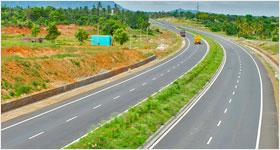

In [9]:
from PIL import Image

manifiesto["ruta_completa"] = manifiesto["ruta_relativa"].apply(
    lambda ruta: RAW / ruta
)

faltantes = manifiesto[
    ~manifiesto["ruta_completa"].apply(lambda ruta: ruta.is_file())
]

print("Imágenes registradas:", len(manifiesto))
print("Imágenes faltantes:", len(faltantes))

if not faltantes.empty:
    display(faltantes[["id", "ruta_relativa"]].head(10))
    raise FileNotFoundError(
        "Hay rutas del CSV que no existen en data/raw."
    )


ruta_prueba = manifiesto.iloc[0]["ruta_completa"]

with Image.open(ruta_prueba) as imagen:
    imagen = imagen.convert("RGB")
    print("Imagen de prueba:", ruta_prueba)
    print("Dimensiones:", imagen.size)
    print("Modo:", imagen.mode)
    display(imagen)

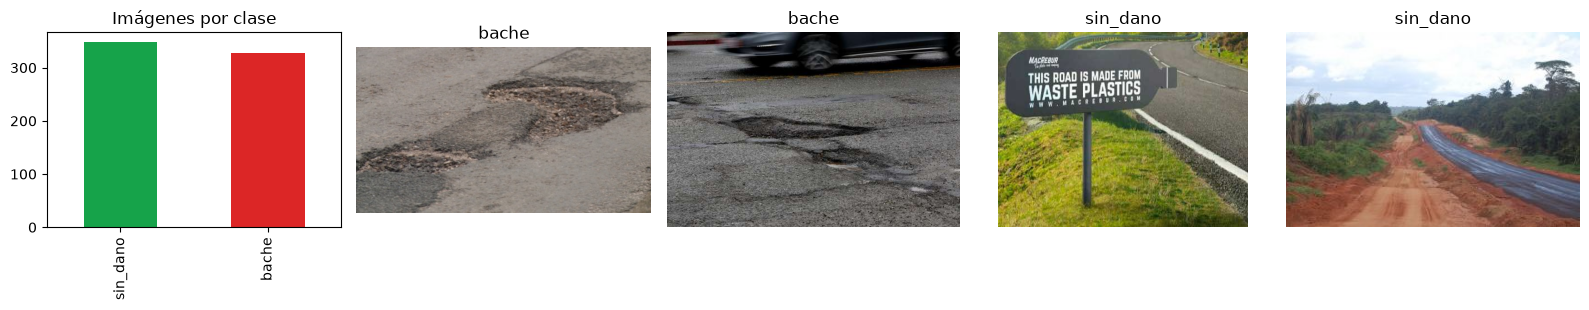

In [10]:
import matplotlib.pyplot as plt
from PIL import Image

CLASES = ["sin_dano", "bache"]

fig, ejes = plt.subplots(1, 5, figsize=(16, 3.2))

manifiesto["clase"].value_counts().reindex(CLASES, fill_value=0).plot.bar(
    ax=ejes[0],
    color=["#16A34A", "#DC2626"]
)

ejes[0].set_title("Imágenes por clase")
ejes[0].set_xlabel("")

ejemplos = pd.concat([
    grupo.sample(n=2, random_state=SEMILLA)
    for _, grupo in manifiesto.groupby("clase")
])

for eje, (_, fila) in zip(ejes[1:], ejemplos.iterrows()):
    with Image.open(RAW / fila["ruta_relativa"]) as imagen:
        eje.imshow(imagen.convert("RGB"))

    eje.set_title(fila["clase"])
    eje.axis("off")

plt.tight_layout()
plt.show()

In [11]:
from src.datos import DICCIONARIO

ruta_resumen = PROYECTO / "data" / "resumen_dataset.json"

if ruta_resumen.is_file():
    resumen = json.loads(ruta_resumen.read_text(encoding="utf-8"))
else:
    resumen = {
        "imagenes_finales": len(manifiesto),
        "semilla": SEMILLA,
        "max_por_clase": MAX_POR_CLASE,
    }

(PROYECTO / "data").mkdir(parents=True, exist_ok=True)

manifiesto_exportar = manifiesto.drop(
    columns=["ruta_completa"], errors="ignore"
)

manifiesto_exportar.to_csv(
    PROYECTO / "data" / "dataset.csv",
    index=False
)

diccionario = pd.DataFrame(
    DICCIONARIO,
    columns=["campo", "tipo", "descripcion"]
)

diccionario.to_csv(
    PROYECTO / "data" / "diccionario_datos.csv",
    index=False
)

(PROYECTO / "data" / "origen_dataset.json").write_text(
    json.dumps(FUENTE_DATASET, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

(PROYECTO / "data" / "resumen_dataset.json").write_text(
    json.dumps(resumen, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

with pd.ExcelWriter(PROYECTO / "data" / "dataset_baches.xlsx") as excel:
    manifiesto_exportar.to_excel(
        excel, sheet_name="dataset", index=False
    )
    diccionario.to_excel(
        excel, sheet_name="diccionario", index=False
    )
    pd.DataFrame(
        list(FUENTE_DATASET.items()),
        columns=["campo", "valor"]
    ).to_excel(excel, sheet_name="origen", index=False)
    pd.DataFrame(
        list(resumen.items()),
        columns=["concepto", "valor"]
    ).to_excel(excel, sheet_name="resumen", index=False)

display(diccionario)
print("Archivos del dataset exportados correctamente.")

,campo,tipo,descripcion
0,id,texto,Identificador único de la imagen.
1,ruta_relativa,texto,Ruta relativa dentro de data/raw.
2,clase,texto,Clase: bache o sin_dano.
3,etiqueta,entero,"1 = bache, 0 = sin_dano."
4,particion,texto,"Partición: train, val o test."
5,ancho_px,entero,Ancho de la imagen en píxeles.
6,alto_px,entero,Alto de la imagen en píxeles.
7,tamano_kb,decimal,Tamaño del archivo en KB.
8,md5,texto,Huella para detectar duplicados.


Archivos del dataset exportados correctamente.


### Carga del dataset con la librería `datasets` de Hugging Face

In [12]:
from datasets import Dataset, Image as ImagenHF

dfs = {p: manifiesto[manifiesto["particion"] == p].reset_index(drop=True) for p in ("train", "val", "test")}

def crear_dataset_hf(df):
    rutas = [str(RAW / r) for r in df["ruta_relativa"]]
    return Dataset.from_dict({"image": rutas, "label": df["etiqueta"].tolist()}).cast_column("image", ImagenHF())

dsets = {p: crear_dataset_hf(df) for p, df in dfs.items()}
print({p: len(d) for p, d in dsets.items()})

{'train': 472, 'val': 102, 'test': 102}


## 6. Modelos candidatos
Elegí tres modelos de tamaños muy distintos para observar el equilibrio entre eficiencia y precisión: MobileNetV2 (ligero), ResNet-50 (mediano) y ViT-Base (grande, basado en transformers). La licencia y la tarea de cada uno se consultan directamente al Hub.

In [13]:
from huggingface_hub import HfApi

api = HfApi()

def info_modelo(model_id):
    try:
        info = api.model_info(model_id)
        licencia = (
            info.card_data.license
            if info.card_data is not None
            else None
        )
        return {
            "id_hub": model_id,
            "tarea_hub": info.pipeline_tag,
            "licencia_hub": licencia,
            "consulta_hub": "correcta",
        }
    except Exception as error:
        return {
            "id_hub": model_id,
            "tarea_hub": None,
            "licencia_hub": None,
            "consulta_hub": f"no disponible ({type(error).__name__})",
        }

info_hub = {
    nombre: info_modelo(model_id)
    for nombre, model_id in MODELOS.items()
}

display(pd.DataFrame(info_hub).T)

,id_hub,tarea_hub,licencia_hub,consulta_hub
MobileNetV2,google/mobilenet_v2_1.0_224,image-classification,other,correcta
ResNet-50,microsoft/resnet-50,image-classification,apache-2.0,correcta
ViT-Base,google/vit-base-patch16-224,image-classification,apache-2.0,correcta


## 7. Pipeline de inferencia, ajuste mínimo y medición
Para cada modelo:
1. Cargo el modelo y su procesador de imágenes desde el Hub.
2. Extraigo los vectores de características de `train`, `val` y `test` con el modelo congelado.
3. Entreno una regresión logística sobre esos vectores y elijo su parámetro `C` con la partición `val`.
4. Evalúo en `test` con accuracy, precision, recall, F1 y AUC.
5. Mido la latencia por imagen en GPU y CPU, la velocidad por lote, la memoria de GPU y el tamaño del modelo.

In [17]:
from transformers import AutoImageProcessor, AutoModel
from torch.utils.data import DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, roc_auc_score


def crear_cargador(ds, procesador):
    def agrupar(lote):
        imagenes = [ej["image"].convert("RGB") for ej in lote]
        pixeles = procesador(
            images=imagenes,
            return_tensors="pt"
        )["pixel_values"]

        etiquetas = torch.tensor(
            [ej["label"] for ej in lote],
            dtype=torch.long
        )
        return pixeles, etiquetas

    return DataLoader(
        ds,
        batch_size=ANCHO_LOTE,
        shuffle=False,
        num_workers=0,
        collate_fn=agrupar
    )


@torch.no_grad()
def vector_caracteristicas(modelo, pixeles):
    salida = modelo(pixel_values=pixeles)

    if modelo.config.model_type == "vit":
        return salida.last_hidden_state[:, 0]

    if hasattr(salida, "pooler_output") and salida.pooler_output is not None:
        return salida.pooler_output.flatten(start_dim=1)

    return salida.last_hidden_state.mean(dim=(2, 3))


@torch.no_grad()
def extraer(modelo, ds, procesador):
    vectores, etiquetas = [], []

    for pixeles, y in crear_cargador(ds, procesador):
        v = vector_caracteristicas(
            modelo, pixeles.to(DISPOSITIVO)
        )
        vectores.append(v.float().cpu().numpy())
        etiquetas.append(y.numpy())

    return np.concatenate(vectores), np.concatenate(etiquetas)


def entrenar_cabeza(X_train, y_train, X_val, y_val):
    mejor = None

    for C in (0.01, 0.1, 1.0, 10.0):
        clf = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=C,
                max_iter=3000,
                class_weight="balanced"
            )
        )
        clf.fit(X_train, y_train)
        f1 = f1_score(
            y_val, clf.predict(X_val), zero_division=0
        )

        if mejor is None or f1 > mejor[0]:
            mejor = (f1, C, clf)

    return mejor[2], mejor[1], mejor[0]


@torch.no_grad()
def una_inferencia(modelo, procesador, cabeza, imagen, dispositivo):
    pixeles = procesador(
        images=imagen.convert("RGB"),
        return_tensors="pt"
    )["pixel_values"].to(dispositivo)

    v = vector_caracteristicas(modelo, pixeles)
    v = v.float().cpu().numpy()

    return cabeza.predict_proba(v)[0, 1]


def medir_latencia(modelo, procesador, cabeza, imagenes, dispositivo):
    modelo.to(dispositivo)
    modelo.eval()

    for im in imagenes[:5]:
        una_inferencia(modelo, procesador, cabeza, im, dispositivo)

    tiempos = []

    for im in imagenes:
        t0 = time.perf_counter()
        una_inferencia(modelo, procesador, cabeza, im, dispositivo)

        if dispositivo.type == "cuda":
            torch.cuda.synchronize()

        tiempos.append((time.perf_counter() - t0) * 1000)

    return {
        "mediana_ms": float(np.median(tiempos)),
        "p95_ms": float(np.percentile(tiempos, 95))
    }


@torch.no_grad()
def medir_rendimiento(modelo, procesador, imagenes):
    modelo.eval()

    lote = procesador(
        images=[im.convert("RGB") for im in imagenes[:ANCHO_LOTE]],
        return_tensors="pt"
    )["pixel_values"].to(DISPOSITIVO)

    for _ in range(2):
        vector_caracteristicas(modelo, lote)

    if HAY_GPU:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    repeticiones = 5
    t0 = time.perf_counter()

    for _ in range(repeticiones):
        vector_caracteristicas(modelo, lote)

    if HAY_GPU:
        torch.cuda.synchronize()

    segundos = time.perf_counter() - t0

    return {
        "imgs_por_seg": len(lote) * repeticiones / segundos,
        "vram_pico_mb": (
            torch.cuda.max_memory_allocated() / 1e6
            if HAY_GPU else None
        )
    }



In [18]:
from src.metricas import calcular_metricas

n_lat = min(N_LATENCIA, len(dsets["test"]))
imagenes_lat = [dsets["test"][i]["image"].convert("RGB") for i in range(n_lat)]

filas, probs = [], {}
for nombre, model_id in MODELOS.items():
    print(f"\n=== {nombre} ({model_id}) ===")
    procesador = AutoImageProcessor.from_pretrained(model_id)
    modelo = AutoModel.from_pretrained(model_id).to(DISPOSITIVO).eval()
    n_param = sum(p.numel() for p in modelo.parameters())

    t0 = time.perf_counter()
    X, y = {}, {}
    for parte in ("train", "val", "test"):
        X[parte], y[parte] = extraer(modelo, dsets[parte], procesador)
    t_extraccion = time.perf_counter() - t0

    cabeza, mejor_C, f1_val = entrenar_cabeza(X["train"], y["train"], X["val"], y["val"])
    prob_test = cabeza.predict_proba(X["test"])[:, 1]
    probs[nombre] = prob_test

    m = calcular_metricas(y["test"], prob_test)
    lat_gpu = medir_latencia(modelo, procesador, cabeza, imagenes_lat, DISPOSITIVO)
    rend = medir_rendimiento(modelo, procesador, imagenes_lat)
    lat_cpu = None
    if MEDIR_CPU:
        modelo.to("cpu")
        lat_cpu = medir_latencia(modelo, procesador, cabeza, imagenes_lat[:30], torch.device("cpu"))

    filas.append({
        "modelo": nombre, "id_hub": model_id, "licencia": info_hub[nombre]["licencia_hub"],
        "parametros_M": n_param / 1e6, "tamano_MB_fp32": n_param * 4 / 1e6,
        "accuracy": m["accuracy"], "precision": m["precision"], "recall": m["recall"], "f1": m["f1"],
        "auc": roc_auc_score(y["test"], prob_test), "C_elegido": mejor_C, "f1_validacion": f1_val,
        "lat_gpu_mediana_ms": lat_gpu["mediana_ms"], "lat_gpu_p95_ms": lat_gpu["p95_ms"],
        "lat_cpu_mediana_ms": lat_cpu["mediana_ms"] if lat_cpu else None,
        "imgs_por_seg_gpu": rend["imgs_por_seg"], "vram_pico_mb": rend["vram_pico_mb"],
        "tiempo_extraccion_s": t_extraccion, "tn": m["tn"], "fp": m["fp"], "fn": m["fn"], "tp": m["tp"],
    })
    print(f"F1={m['f1']:.4f} | accuracy={m['accuracy']:.4f} | latencia GPU={lat_gpu['mediana_ms']:.1f} ms")
    del modelo
    if HAY_GPU:
        torch.cuda.empty_cache()


=== MobileNetV2 (google/mobilenet_v2_1.0_224) ===


Loading weights:   0%|          | 0/312 [00:00<?, ?it/s]

[transformers] MobileNetV2Model LOAD REPORT from: google/mobilenet_v2_1.0_224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


F1=0.9592 | accuracy=0.9608 | latencia GPU=18.7 ms

=== ResNet-50 (microsoft/resnet-50) ===


Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.bias     | UNEXPECTED | 
classifier.weight   | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


F1=0.9897 | accuracy=0.9902 | latencia GPU=14.7 ms


## 8. Resultados

In [19]:
tabla = pd.DataFrame(filas)
tabla.to_csv(RESULTADOS / "metricas_modelos.csv", index=False)
resumen_tabla = tabla[["modelo", "licencia", "parametros_M", "tamano_MB_fp32", "accuracy", "precision", "recall", "f1",
                       "auc", "lat_gpu_mediana_ms", "lat_cpu_mediana_ms", "imgs_por_seg_gpu", "vram_pico_mb"]]
display(resumen_tabla.round(3))

,modelo,licencia,parametros_M,tamano_MB_fp32,accuracy,precision,recall,f1,auc,lat_gpu_mediana_ms,lat_cpu_mediana_ms,imgs_por_seg_gpu,vram_pico_mb
0,MobileNetV2,other,2.224,8.895,0.961,0.959,0.959,0.959,0.995,18.663,27.803,326.219,108.367
1,ResNet-50,apache-2.0,23.508,94.032,0.990,0.980,1.000,0.990,0.997,16.104,59.994,288.770,189.011
2,ViT-Base,apache-2.0,86.389,345.557,0.990,1.000,0.980,0.990,0.998,14.691,152.838,168.652,418.064


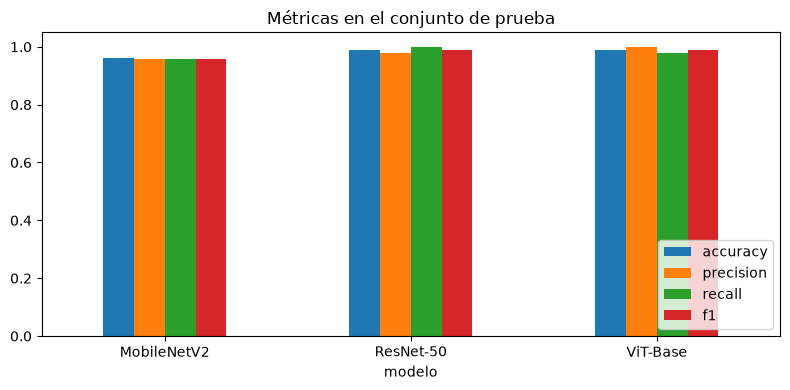

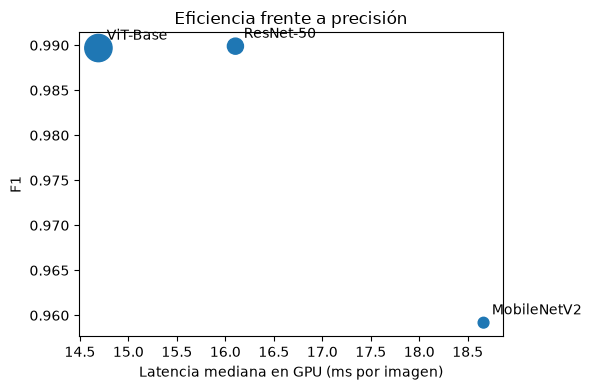

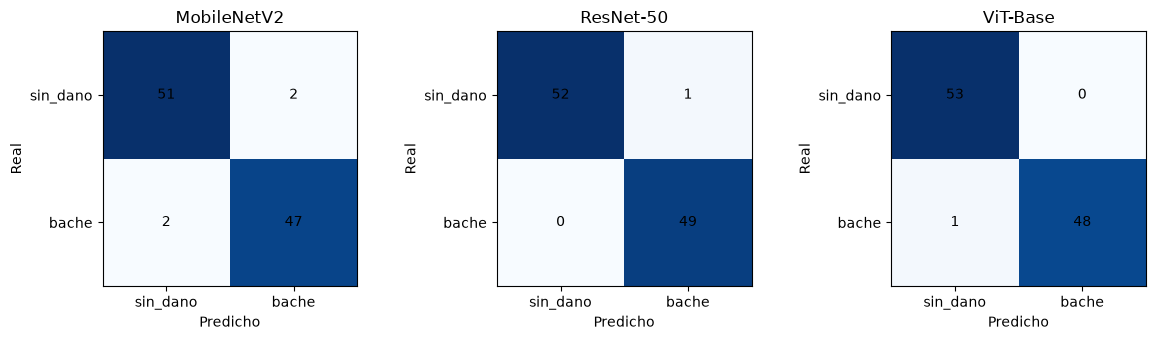

In [20]:
import matplotlib.pyplot as plt

ax = tabla.set_index("modelo")[["accuracy", "precision", "recall", "f1"]].plot.bar(figsize=(8, 4), rot=0, ylim=(0, 1.05))
ax.set_title("Métricas en el conjunto de prueba"); ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig(RESULTADOS / "metricas_por_modelo.png", dpi=150); plt.show()

fig, eje = plt.subplots(figsize=(6, 4))
eje.scatter(tabla["lat_gpu_mediana_ms"], tabla["f1"], s=tabla["parametros_M"].clip(lower=5) * 4 + 40)
for _, f in tabla.iterrows():
    eje.annotate(f["modelo"], (f["lat_gpu_mediana_ms"], f["f1"]), textcoords="offset points", xytext=(6, 6))
eje.set_xlabel("Latencia mediana en GPU (ms por imagen)"); eje.set_ylabel("F1"); eje.set_title("Eficiencia frente a precisión")
plt.tight_layout(); plt.savefig(RESULTADOS / "eficiencia_vs_precision.png", dpi=150); plt.show()

fig, ejes = plt.subplots(1, len(tabla), figsize=(4 * len(tabla), 3.5))
ejes = np.atleast_1d(ejes)
for eje, (_, f) in zip(ejes, tabla.iterrows()):
    matriz = np.array([[f["tn"], f["fp"]], [f["fn"], f["tp"]]])
    eje.imshow(matriz, cmap="Blues")
    for i in range(2):
        for j in range(2):
            eje.text(j, i, int(matriz[i, j]), ha="center", va="center")
    eje.set_xticks([0, 1], ["sin_dano", "bache"]); eje.set_yticks([0, 1], ["sin_dano", "bache"])
    eje.set_xlabel("Predicho"); eje.set_ylabel("Real"); eje.set_title(f["modelo"])
plt.tight_layout(); plt.savefig(RESULTADOS / "matrices_confusion.png", dpi=150); plt.show()

## 9. Umbrales de decisión
En UrbanOS no detectar un bache real pesa más que una falsa alarma, por eso reviso cómo cambian precision y recall al mover el umbral con el que se decide que hay un bache.

In [21]:
from src.metricas import tabla_umbrales

y_test = dfs["test"]["etiqueta"].to_numpy()
umbrales = pd.concat(
    [tabla_umbrales(y_test, p).assign(modelo=nombre) for nombre, p in probs.items()], ignore_index=True
)
umbrales.to_csv(RESULTADOS / "umbrales_modelos.csv", index=False)

mejor = tabla.loc[tabla["f1"].idxmax(), "modelo"]
print("Modelo con mejor F1:", mejor)
display(umbrales[umbrales["modelo"] == mejor].round(3))

Modelo con mejor F1: ResNet-50


,umbral,accuracy,precision,recall,f1,fp,fn,modelo
7,0.2,0.980,0.961,1.000,0.980,2,0,ResNet-50
8,0.3,0.980,0.961,1.000,0.980,2,0,ResNet-50
9,0.4,0.980,0.961,1.000,0.980,2,0,ResNet-50
10,0.5,0.990,0.980,1.000,0.990,1,0,ResNet-50
11,0.6,0.971,0.979,0.959,0.969,1,2,ResNet-50
12,0.7,0.961,0.979,0.939,0.958,1,3,ResNet-50
13,0.8,0.961,0.979,0.939,0.958,1,3,ResNet-50


## 10. Errores del mejor modelo

Errores de ResNet-50 en prueba (102 imágenes): 0 falsos negativos, 1 falsas alarmas


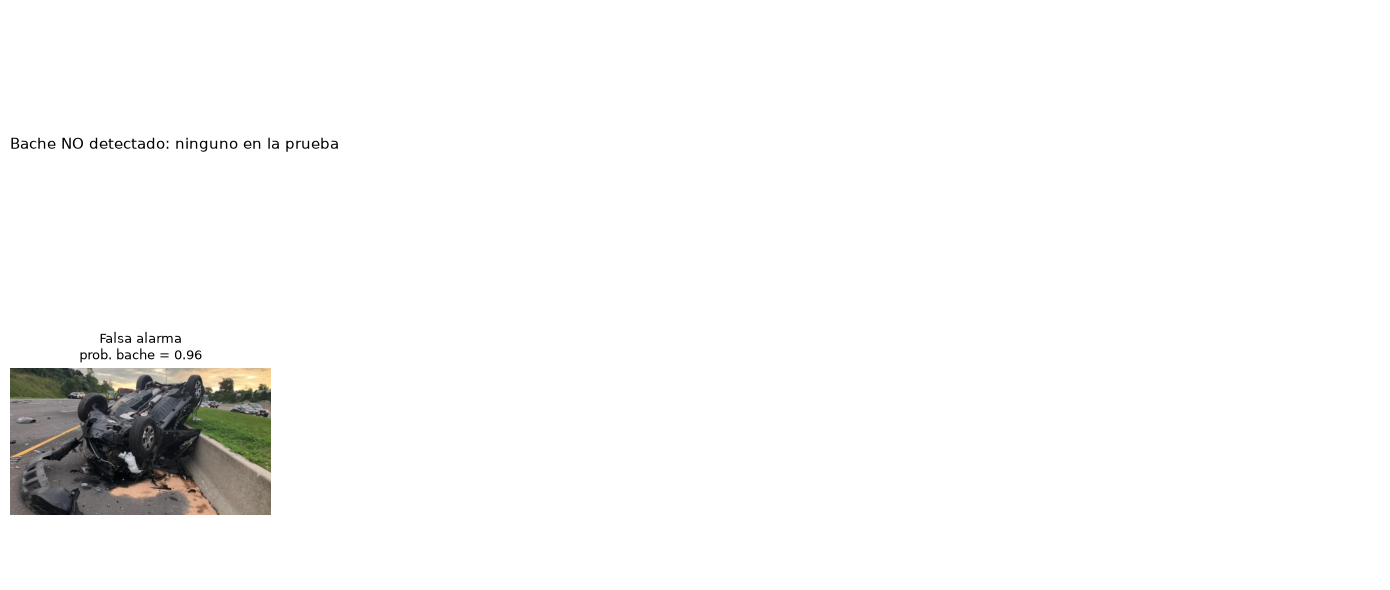

In [22]:
prob_mejor = probs[mejor]

prueba = dfs["test"].assign(prob=prob_mejor)

falsos_negativos = prueba[
    (prueba["etiqueta"] == 1) & (prueba["prob"] < 0.5)
].sort_values("prob")

falsos_positivos = prueba[
    (prueba["etiqueta"] == 0) & (prueba["prob"] >= 0.5)
].sort_values("prob", ascending=False)

print(
    f"Errores de {mejor} en prueba ({len(prueba)} imágenes): "
    f"{len(falsos_negativos)} falsos negativos, "
    f"{len(falsos_positivos)} falsas alarmas"
)

fig, ejes = plt.subplots(2, 4, figsize=(14, 6))

for fila_ejes, (titulo, datos) in zip(
    ejes,
    [
        ("Bache NO detectado", falsos_negativos),
        ("Falsa alarma", falsos_positivos),
    ]
):
    for eje in fila_ejes:
        eje.axis("off")

    if datos.empty:
        fila_ejes[0].text(
            0, 0.5,
            f"{titulo}: ninguno en la prueba",
            fontsize=11,
            transform=fila_ejes[0].transAxes
        )

    for eje, (_, f) in zip(fila_ejes, datos.head(4).iterrows()):
        ruta_imagen = RAW / f["ruta_relativa"]

        with Image.open(ruta_imagen) as imagen:
            eje.imshow(imagen.convert("RGB").copy())

        eje.set_title(
            f"{titulo}\nprob. bache = {f['prob']:.2f}",
            fontsize=9
        )

plt.tight_layout()
plt.savefig(
    RESULTADOS / "errores_mejor_modelo.png",
    dpi=150
)
plt.show()

## 11. Conclusiones parciales

In [23]:
mejor_f1 = tabla.loc[tabla["f1"].idxmax()]
mas_rapido = tabla.loc[tabla["lat_gpu_mediana_ms"].idxmin()]
mas_ligero = tabla.loc[tabla["tamano_MB_fp32"].idxmin()]
mayor_recall = tabla.loc[tabla["recall"].idxmax()]

print(f"• Mejor F1: {mejor_f1['modelo']} ({mejor_f1['f1']:.3f}), con accuracy {mejor_f1['accuracy']:.3f}.")
print(f"• Mayor recall: {mayor_recall['modelo']} ({mayor_recall['recall']:.3f}).")
print(f"• Más rápido en GPU: {mas_rapido['modelo']} ({mas_rapido['lat_gpu_mediana_ms']:.1f} ms por imagen).")
print(f"• Más ligero: {mas_ligero['modelo']} ({mas_ligero['parametros_M']:.1f} M de parámetros, {mas_ligero['tamano_MB_fp32']:.0f} MB).")
if mejor_f1["modelo"] != mas_rapido["modelo"]:
    print(f"• El más preciso ({mejor_f1['modelo']}) no es el más rápido ({mas_rapido['modelo']}).")
else:
    print(f"• {mejor_f1['modelo']} es a la vez el más preciso y el más rápido.")

• Mejor F1: ResNet-50 (0.990), con accuracy 0.990.
• Mayor recall: ResNet-50 (1.000).
• Más rápido en GPU: ViT-Base (14.7 ms por imagen).
• Más ligero: MobileNetV2 (2.2 M de parámetros, 9 MB).
• El más preciso (ResNet-50) no es el más rápido (ViT-Base).


## 12. Guardar entregables

In [24]:

from importlib.metadata import version

paquetes = [
    "torch",
    "transformers",
    "datasets",
    "huggingface_hub",
    "scikit-learn",
    "pandas",
    "numpy",
    "matplotlib",
    "openpyxl",
    "pillow",
]

lineas = [f"{p}=={version(p)}" for p in paquetes]

(RESULTADOS / "requirements_local.txt").write_text(
    "\n".join(lineas) + "\n",
    encoding="utf-8",
)

(RESULTADOS / "entorno.json").write_text(
    json.dumps(
        {
            "python": sys.version.split()[0],
            "gpu": torch.cuda.get_device_name(0) if HAY_GPU else None,
            "semilla": SEMILLA,
            "modelos": MODELOS,
        },
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

predicciones = dfs["test"][["id", "clase", "etiqueta"]].copy()

for nombre, p in probs.items():
    predicciones[f"prob_bache_{nombre}"] = p

predicciones.to_csv(
    RESULTADOS / "predicciones_test.csv",
    index=False,
)

destino = RESULTADOS / "entregables_urbanos.zip"

with zipfile.ZipFile(destino, "w", zipfile.ZIP_DEFLATED) as z:
    for ruta in PROYECTO.rglob("*"):
        if not ruta.is_file():
            continue

        if ruta == destino:
            continue

        if RAW in ruta.parents:
            continue

        if ".venv" in ruta.parts or "__pycache__" in ruta.parts:
            continue

        if ".ipynb_checkpoints" in ruta.parts:
            continue

        z.write(ruta, ruta.relative_to(PROYECTO))

print(
    "ZIP listo:",
    destino,
    f"({destino.stat().st_size / 1e6:.1f} MB)",
)

print("\n".join(lineas))

ZIP listo: c:\Users\Eduardo\Desktop\Dev\Proyectos\urbanos\ml\results\entregables_urbanos.zip (1.1 MB)
torch==2.11.0+cu128
transformers==5.19.0
datasets==5.1.0
huggingface_hub==2.2.0
scikit-learn==1.9.1
pandas==3.0.6
numpy==2.4.6
matplotlib==3.11.2
openpyxl==3.1.5
pillow==12.3.0
